In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

DATA_PROCESSED = Path.cwd() / "data" / "processed"
if not DATA_PROCESSED.exists():
    DATA_PROCESSED = Path.cwd().parent / "data" / "processed"

first_2 = pd.read_csv(DATA_PROCESSED / "complaints_jan_feb.csv")
june_july = pd.read_csv(DATA_PROCESSED / "complaints_jun_jul.csv")

In [3]:
# Group same types together
first_2_grouped = first_2.groupby('Complaint Type', as_index=False).sum()
june_july_grouped = june_july.groupby('Complaint Type', as_index=False).sum()

In [4]:
# Sort descending
first_2_grouped = first_2_grouped.sort_values( by="Count", ascending=False )
june_july_grouped = june_july_grouped.sort_values( by="Count", ascending=False )

In [5]:
# take highest
name_first_2 = first_2_grouped.iloc[0]['Complaint Type']

In [6]:
# keep type complaint and also sort in Alpha.
first_2 = first_2[first_2['Complaint Type'] == name_first_2]
first_2 = first_2.sort_values(by="Borough")

# For june july keep same complaint type 
june_july = june_july[june_july['Complaint Type'] == name_first_2]
june_july = june_july.sort_values(by="Borough")

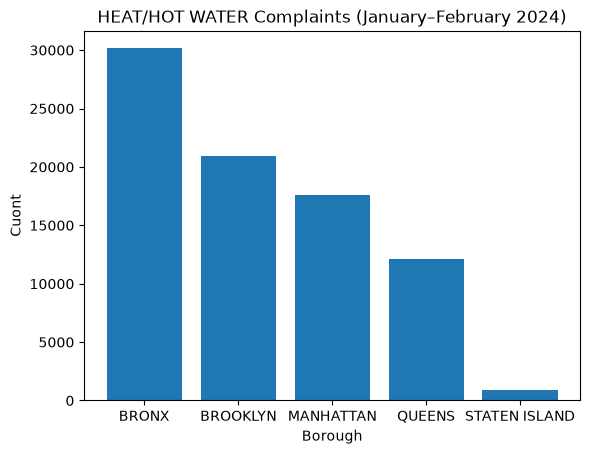

In [7]:
# Make feb bar
plt.bar(first_2["Borough"], first_2["Count"])

plt.xlabel("Borough")
plt.ylabel("Cuont")
plt.title(f"{name_first_2} Complaints (January–February 2024)")

plt.show()

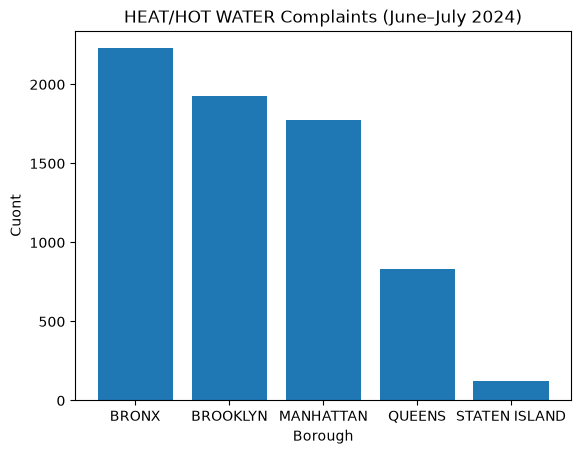

In [8]:
# Make june july bar
plt.bar(june_july["Borough"], june_july["Count"])

plt.xlabel("Borough")
plt.ylabel("Cuont")
plt.title(f"{name_first_2} Complaints (June–July 2024)")

plt.show()